In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [2]:
# ==============================================================================
# 1. LOAD DATA (ADVANCED TIMESFM FEATURES ONLY)
# ==============================================================================
print("Loading Advanced TimesFM Meta-Features...")
# Load the dataset generated in Notebook 04b
X_tfm_adv = pd.read_parquet('../data/processed/features_timesfm.parquet')
y_train = pd.read_parquet('../data/raw/y_train.parquet')

# Ensure perfect alignment between features and target using the index ('id')
y = y_train.loc[X_tfm_adv.index]['structural_breakpoint']

print(f"Features shape: {X_tfm_adv.shape}")
print(f"Target shape: {y.shape}")

# Calculate the exact class imbalance ratio for scale_pos_weight
imbalance_ratio = (y == 0).sum() / (y == 1).sum()
print(f"Class imbalance ratio (False/True): {imbalance_ratio:.4f}")

Loading Advanced TimesFM Meta-Features...
Features shape: (10001, 782)
Target shape: (10001,)
Class imbalance ratio (False/True): 2.4380


In [3]:
# ==============================================================================
# 2. MODEL EVALUATION (5-FOLD CROSS VALIDATION)
# ==============================================================================
# Base parameters keeping the scale_pos_weight to favor minority class recall
base_params = {
    'n_estimators': 300, 
    'learning_rate': 0.05, 
    'max_depth': 5, 
    'subsample': 0.8, 
    'colsample_bytree': 0.8, 
    'scale_pos_weight': imbalance_ratio, 
    'eval_metric': 'auc', 
    'random_state': 42, 
    'n_jobs': -1,
    'enable_categorical': True
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
xgb_model = xgb.XGBClassifier(**base_params)

print("\n" + "="*50)
print("EVALUATING MODEL: ADVANCED TIMESFM FEATURES ONLY")
print("="*50)

# Calculate ROC AUC
scores_auc = cross_val_score(xgb_model, X_tfm_adv, y, cv=cv_strategy, scoring='roc_auc', n_jobs=-1)
mean_auc = np.mean(scores_auc)
std_auc = np.std(scores_auc)

print(f"Mean ROC AUC: {mean_auc:.4f} (+/- {std_auc:.4f})")

# Generate cross-validated predictions for the classification report
y_pred_cv = cross_val_predict(xgb_model, X_tfm_adv, y, cv=cv_strategy, n_jobs=-1)

print("\nCLASSIFICATION REPORT:")
print(classification_report(y, y_pred_cv, digits=4))


EVALUATING MODEL: ADVANCED TIMESFM FEATURES ONLY
Mean ROC AUC: 0.5434 (+/- 0.0123)

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

       False     0.7223    0.8308    0.7728      7092
        True     0.3492    0.2214    0.2710      2909

    accuracy                         0.6535     10001
   macro avg     0.5358    0.5261    0.5219     10001
weighted avg     0.6138    0.6535    0.6268     10001



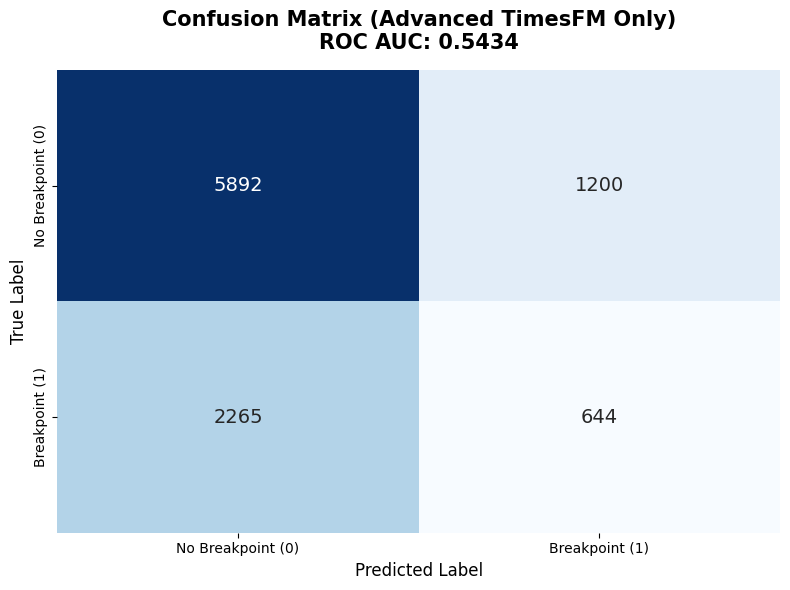

In [4]:
# ==============================================================================
# 3. CONFUSION MATRIX VISUALIZATION
# ==============================================================================
cm = confusion_matrix(y, y_pred_cv)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Breakpoint (0)', 'Breakpoint (1)'],
            yticklabels=['No Breakpoint (0)', 'Breakpoint (1)'],
            annot_kws={"size": 14})

plt.title(f'Confusion Matrix (Advanced TimesFM Only)\nROC AUC: {mean_auc:.4f}', 
          fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()


Extracting Feature Importances to understand DGP anomalies...


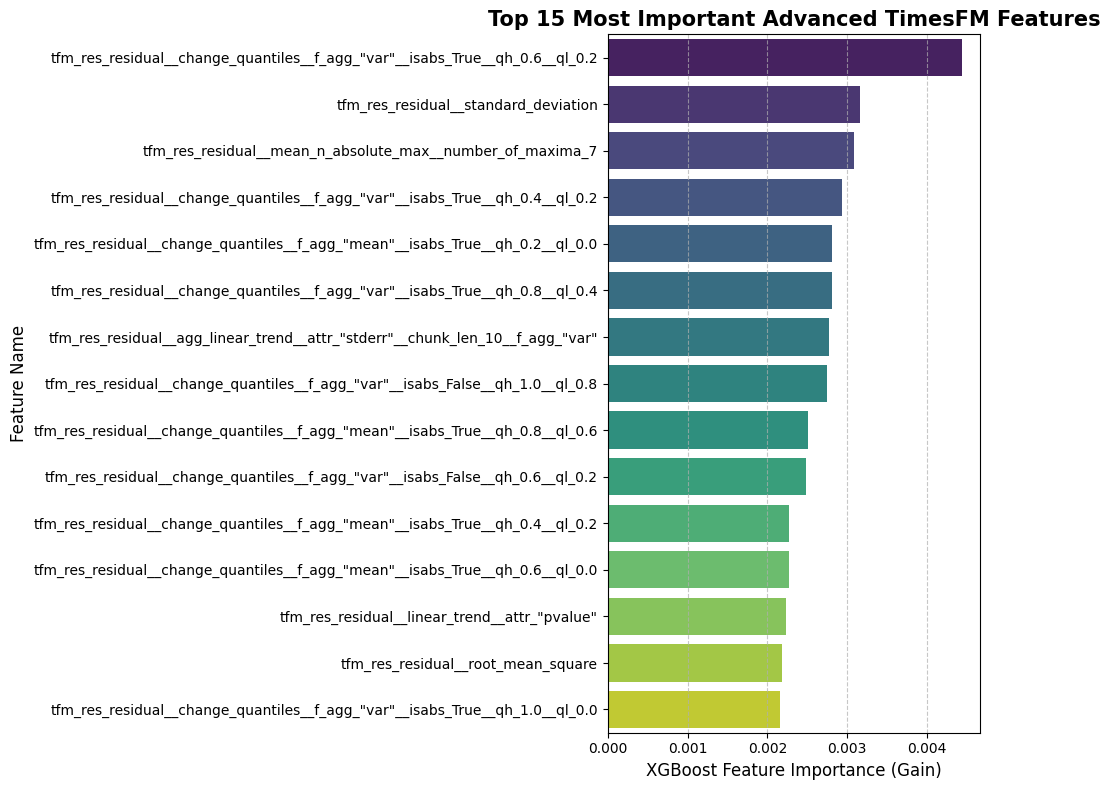


Top 10 Feature Importance Weights:


,Feature,Importance
0,"tfm_res_residual__change_quantiles__f_agg_""var...",0.004444
1,tfm_res_residual__standard_deviation,0.003167
2,tfm_res_residual__mean_n_absolute_max__number_...,0.003090
3,"tfm_res_residual__change_quantiles__f_agg_""var...",0.002941
4,"tfm_res_residual__change_quantiles__f_agg_""mea...",0.002815
5,"tfm_res_residual__change_quantiles__f_agg_""var...",0.002814
6,"tfm_res_residual__agg_linear_trend__attr_""stde...",0.002767
7,"tfm_res_residual__change_quantiles__f_agg_""var...",0.002746
8,"tfm_res_residual__change_quantiles__f_agg_""mea...",0.002510
9,"tfm_res_residual__change_quantiles__f_agg_""var...",0.002482


In [5]:
# ==============================================================================
# 4. FEATURE IMPORTANCE ANALYSIS
# ==============================================================================
print("\nExtracting Feature Importances to understand DGP anomalies...")

# Fit the model on the entire dataset to extract the global importance
xgb_model.fit(X_tfm_adv, y)

# Extract and sort importances
importances = xgb_model.feature_importances_
df_importances = pd.DataFrame({
    'Feature': X_tfm_adv.columns, 
    'Importance': importances
})
df_importances = df_importances.sort_values(by='Importance', ascending=False).reset_index(drop=True)

# Plot the Top 15 most important features
plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=df_importances.head(15), palette='viridis')

plt.title('Top 15 Most Important Advanced TimesFM Features', fontsize=15, fontweight='bold')
plt.xlabel('XGBoost Feature Importance (Gain)', fontsize=12)
plt.ylabel('Feature Name', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Display the exact weights
print("\nTop 10 Feature Importance Weights:")
display(df_importances.head(10))